## Dataset A. Baummanni

In [65]:

import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import Normalize
import numpy as np

import json
import csv

from geopy.geocoders import Nominatim
from geopy.point import Point
from matplotlib.patches import Patch

In [2]:
df = pd.read_csv("A_baumannii_metadata.tsv", sep="\t")
df.columns

Index(['Assembly Accession', 'Organism Name', 'Assembly BioSample Accession',
       'Assembly BioSample Isolate', 'Assembly BioSample Strain',
       'Assembly BioSample Geographic location',
       'Assembly BioSample Latitude and Longitude',
       'Assembly BioSample Isolation source', 'Assembly BioSample Host',
       'Assembly BioSample Collection date'],
      dtype='object')

In [3]:
df.head()

,Assembly Accession,Organism Name,Assembly BioSample Accession,Assembly BioSample Isolate,Assembly BioSample Strain,Assembly BioSample Geographic location,Assembly BioSample Latitude and Longitude,Assembly BioSample Isolation source,Assembly BioSample Host,Assembly BioSample Collection date
0,GCF_000248195.1,Acinetobacter baumannii,SAMN02471590,NaN,NCTC 7422,United Kingdom: Manchester,NaN,leg burn,Homo sapiens,1948-01-01
1,GCF_000695855.3,Acinetobacter baumannii,SAMN02714232,NaN,AC29,"Malaysia: Kuala Terengganu, Terengganu",5.311737 N 103.119912 E,Endotracheal Secretion,Homo sapiens,2011-07-31
2,GCF_000708775.1,Acinetobacter baumannii,SAMN02803875,NaN,BR097,USA: KY,38.25 N 85.76 W,sputum,Homo sapiens,2012-11-08
3,GCF_000708795.1,Acinetobacter baumannii,SAMN02803891,NaN,BU310,USA: KY,38.25 N 85.76 W,urinary catheter,Homo sapiens,2012-10-28
4,GCF_000731965.1,Acinetobacter baumannii,SAMN02821219,BM4587,NaN,France,missing,missing,Homo sapiens,missing


### Observando a coluna "Assembly BioSample Geographic location"

In [4]:
print(
    df["Assembly BioSample Geographic location"]
    .drop_duplicates()
    .to_string(index=False)
)

                        United Kingdom: Manchester
            Malaysia: Kuala Terengganu, Terengganu
                                           USA: KY
                                            France
                                   China: Zhejiang
                                      USA: Chicago
                                    Canada:Toronto
                                  Canada: Winnipeg
                           Argentina: Buenos Aires
                                    not applicable
                                        Japan:Gifu
                                             Japan
                                 Thailand: Bangkok
                                          Malaysia
                                    China: Beijing
                                         Australia
                                  China: Guangdong
                                    China: Jiangsu
                                   China: Shandong
                               

### Observando a coluna "Assembly BioSample Geographic location"

In [5]:
print(
    df["Assembly BioSample Latitude and Longitude"]
    .drop_duplicates()
    .to_string(index=False)
)

                         NaN
     5.311737 N 103.119912 E
             38.25 N 85.76 W
                     missing
             41.89 N 87.62 W
               43.7 N 79.4 W
             50.00 N 98.00 W
             34.34 S 58.33 W
              not applicable
             34.58 S 58.41 W
          13.75 N 100.4667 E
               41.5 N 81.7 W
              2.59 N 75.18 W
                52.9 N 1.1 W
     34.581389 S 58.406944 W
                   18 N 66 W
              44.6 N 123.9 W
              47.5 N 120.5 W
              45.7 N 122.5 W
              45.5 N 123.1 W
              44.9 N 122.6 W
              45.5 N 123.7 W
      38.976556 N 77.02875 W
        35.6833 N 139.7667 E
         3.1333 N 101.7000 E
             1.30 N 103.80 E
         1.3000 N 103.8000 E
    30.256769 N 120.201838 E
             12.92 N 79.13 E
        53.5333 N 113.5000 W
        33.8650 S 151.2094 E
     48.81471 N 2.36072999 E
               not collected
         30.0000 S 25.0000 E
          52.6

## Procurando os países relacionados a cada genoma

In [6]:
paises_localizacaogeografica = df["Assembly BioSample Geographic location"].copy().str.split(":", n=1).str[0]
#paises.unique() 
# remover: not applicable, nan, missing, not collected, not provided, not determined
# Nome estranho: Viet Nam

paises_longitudelatitude = df["Assembly BioSample Latitude and Longitude"].copy()


In [7]:
geolocator = Nominatim(user_agent="ncbi_genome_analysis_country2", timeout=30)

def encontrar_pais(coordenada):
    try:
        ponto = Point(str(coordenada).strip())
        
        local = geolocator.reverse(
            ponto,
            language="en",
            addressdetails=True
        )

        pais = local.raw["address"].get("country")
        return pais

    #except:
    except Exception as erro:
        print(type(erro).__name__, erro, coordenada)
        return np.nan

In [8]:
remover = {"not applicable", "missing", "not collected", "not provided", "not determined", ""}

def valor_valido(valor):
    """Verifica se o valor existe e não corresponde a um termo inválido."""
    if pd.isna(valor):
        return False

    valor_normalizado = str(valor).strip().lower()
    return valor_normalizado not in remover

nome_paises = []
cache = {}

for geo, longlat in zip( paises_localizacaogeografica,paises_longitudelatitude):
    # Prioriza o país informado na localização geográfica
    if valor_valido(geo):
        nome_paises.append(str(geo).strip())

    # Se não houver país, tenta obtê-lo pelas coordenadas
    elif valor_valido(longlat):
        coordenada = str(longlat).strip()

        # Consulta somente se a coordenada ainda não estiver no cache
        if coordenada not in cache:
            cache[coordenada] = encontrar_pais(coordenada)

        pais_encontrado = cache[coordenada]

        if valor_valido(pais_encontrado):
            nome_paises.append(str(pais_encontrado).strip())
        else:
            nome_paises.append(np.nan)

    # Se localização e coordenadas forem inválidas
    else:
        nome_paises.append(np.nan)

df["nome_paises"] = nome_paises

In [9]:
df = df.copy().dropna(subset=["nome_paises"]).reset_index(drop=True)
df.head()

,Assembly Accession,Organism Name,Assembly BioSample Accession,Assembly BioSample Isolate,Assembly BioSample Strain,Assembly BioSample Geographic location,Assembly BioSample Latitude and Longitude,Assembly BioSample Isolation source,Assembly BioSample Host,Assembly BioSample Collection date,nome_paises
0,GCF_000248195.1,Acinetobacter baumannii,SAMN02471590,NaN,NCTC 7422,United Kingdom: Manchester,NaN,leg burn,Homo sapiens,1948-01-01,United Kingdom
1,GCF_000695855.3,Acinetobacter baumannii,SAMN02714232,NaN,AC29,"Malaysia: Kuala Terengganu, Terengganu",5.311737 N 103.119912 E,Endotracheal Secretion,Homo sapiens,2011-07-31,Malaysia
2,GCF_000708775.1,Acinetobacter baumannii,SAMN02803875,NaN,BR097,USA: KY,38.25 N 85.76 W,sputum,Homo sapiens,2012-11-08,USA
3,GCF_000708795.1,Acinetobacter baumannii,SAMN02803891,NaN,BU310,USA: KY,38.25 N 85.76 W,urinary catheter,Homo sapiens,2012-10-28,USA
4,GCF_000731965.1,Acinetobacter baumannii,SAMN02821219,BM4587,NaN,France,missing,missing,Homo sapiens,missing,France


## Mapa global

In [10]:
df_frequencia = (df["nome_paises"].copy().value_counts().rename_axis("pais").reset_index(name="frequencia"))

df_frequencia.head()

df_frequencia["frequencia"] = np.log10(df_frequencia["frequencia"])
df_frequencia

,pais,frequencia
0,USA,4.410355
1,China,4.175657
2,Saudi Arabia,3.409933
3,India,3.254306
4,Thailand,3.214049
...,...,...
120,El Salvador,0.301030
121,Nicaragua,0.301030
122,Djibouti,0.301030
123,Papua New Guinea,0.000000


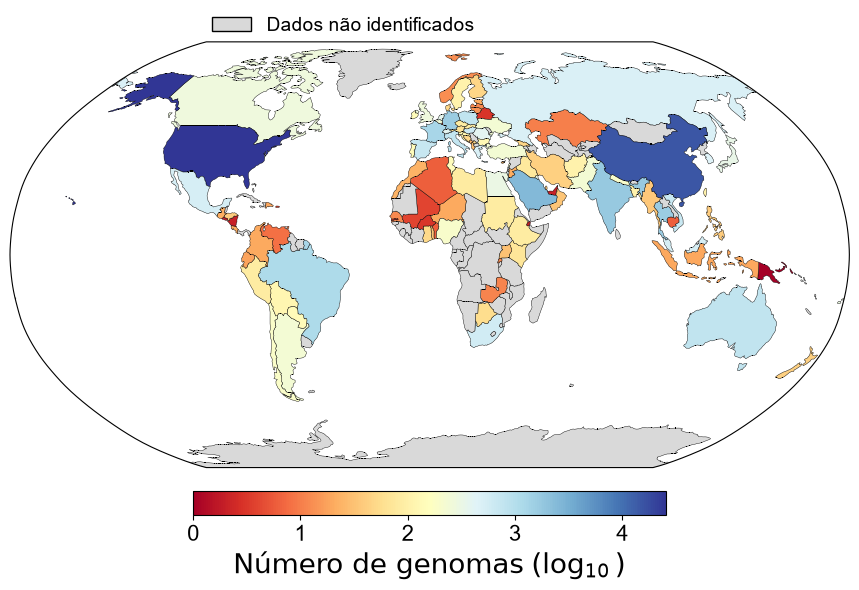

In [100]:
world = gpd.read_file("110m_cultural/ne_110m_admin_0_countries.shp")

names = {"Viet Nam": "Vietnam", "USA": "United States of America"}

# Normaliza os nomes antes da junção
df_frequencia["pais_mapa"] = (df_frequencia["pais"].replace(names).str.strip())

# Une o mapa à tabela de frequências
world = world.merge(df_frequencia[["pais_mapa", "frequencia"]], left_on="ADMIN", right_on="pais_mapa",how="left")

# Mantém NaN para distinguir ausência de frequência igual a zero
max_val = world["frequencia"].max()
min_val = world["frequencia"].min()

#norm = Normalize(vmin=0, vmax=max_val)
norm = Normalize(vmin=round(min_val, 2), vmax=round(max_val, 2))

cmap = plt.colormaps["RdYlBu"]

fig = plt.figure(figsize=(12, 6), facecolor="white")

ax = plt.axes(projection=ccrs.Robinson())

ax.set_global()
ax.set_facecolor("white")

for _, row in world.iterrows():
    if pd.isna(row["frequencia"]):
        cor = "#d9d9d9"
    else:
        cor = cmap(norm(row["frequencia"]))

    ax.add_geometries(
        [row["geometry"]],
        crs=ccrs.PlateCarree(),
        facecolor=cor,
        edgecolor="black",
        linewidth=0.3
    )

sm = plt.cm.ScalarMappable(cmap=cmap,norm=norm)

sm.set_array([])

cbar = plt.colorbar(sm,ax=ax,orientation="horizontal",pad=0.05,fraction=0.05)

cbar.set_label(r"$\mathrm{Número\ de\ genomas}\;(\log_{10})$", fontsize=20, fontfamily="Arial")


cbar.ax.tick_params(labelsize=16)
for tick in cbar.ax.get_xticklabels():
    tick.set_fontfamily("Arial")


legenda_sem_dados = Patch(facecolor="#d9d9d9",edgecolor="black",label="Dados não identificados")

#ax.legend(handles=[legenda_sem_dados],loc="lower left",frameon=False,prop={"family": "Arial", "size": 14})
ax.legend(handles=[legenda_sem_dados],loc="upper left",bbox_to_anchor=(0.22, 1.1),
    frameon=False, prop={"family": "Arial", "size": 14})


plt.tight_layout()
plt.savefig("mapa_deposito.png", dpi=600, bbox_inches="tight")

## Mapa no Brasil

In [18]:
df_brasil = df[df["nome_paises"] == "Brazil"].copy()
df_brasil.head()

,Assembly Accession,Organism Name,Assembly BioSample Accession,Assembly BioSample Isolate,Assembly BioSample Strain,Assembly BioSample Geographic location,Assembly BioSample Latitude and Longitude,Assembly BioSample Isolation source,Assembly BioSample Host,Assembly BioSample Collection date,nome_paises
265,GCF_000988155.1,Acinetobacter baumannii,SAMN03456260,NaN,CCBH5233,Brazil,NaN,NaN,Homo sapiens,2009-08-21,Brazil
389,GCF_001420305.1,Acinetobacter baumannii,SAMN04196795,NaN,Ab25,"Brazil: Hospital das Clinicas, Sao Paulo",not collected,blood,Homo sapiens,2011,Brazil
390,GCF_001420325.1,Acinetobacter baumannii,SAMN04196793,NaN,Ab18,"Brazil: Hospital das Clinicas, Sao Paulo",not collected,blood,Homo sapiens,2004,Brazil
391,GCF_001420335.1,Acinetobacter baumannii,SAMN04196794,NaN,Ab23,"Brazil: Hospital das Clinicas, Sao Paulo",not collected,rectal swab,Homo sapiens,2012,Brazil
392,GCF_001420385.1,Acinetobacter baumannii,SAMN04196796,NaN,Ab28,"Brazil: Hospital das Clinicas, Sao Paulo",not collected,blood,Homo sapiens,2011,Brazil


In [19]:
estados_localizacaogeografica = df_brasil["Assembly BioSample Geographic location"].copy().str.split(":", n=1).str[1]
estados_localizacaogeografica = estados_localizacaogeografica.str.split(",")
#estados.unique() 
# remover: not applicable, nan, missing, not collected, not provided, not determined
# Nome estranho: Viet Nam

estados_longitudelatitude = df_brasil["Assembly BioSample Latitude and Longitude"].copy()


estados_localizacaogeografica # Estados em split

265                                       NaN
389      [ Hospital das Clinicas,  Sao Paulo]
390      [ Hospital das Clinicas,  Sao Paulo]
391      [ Hospital das Clinicas,  Sao Paulo]
392      [ Hospital das Clinicas,  Sao Paulo]
                         ...                 
65122                                     NaN
65123                                     NaN
65124                                     NaN
65126                                     NaN
65228                  [ Fernando de Noronha]
Name: Assembly BioSample Geographic location, Length: 1128, dtype: object

In [20]:
geolocator = Nominatim(user_agent="ncbi_genome_analysis_states-brazil", timeout=30)

def encontrar_estado(coordenada):
    try:
        ponto = Point(str(coordenada).strip())

        local = geolocator.reverse(
            ponto,
            language="en",
            addressdetails=True
        )

        if local is None:
            return np.nan

        return local.raw["address"].get("state", np.nan)

    except Exception as erro:
        print(type(erro).__name__, erro, coordenada)
        return np.nan

In [21]:
ESTADOS_BR = {"acre", "alagoas", "amapa", "amazonas", "bahia", "ceara",
    "distrito federal", "espirito santo", "goias", "maranhao", "mato grosso",
    "mato grosso do sul", "minas gerais", "para", "paraiba", "parana", "pernambuco",
    "piaui", "rio de janeiro", "rio grande do norte", "rio grande do sul", "rondonia",
    "roraima", "santa catarina", "sao paulo", "sergipe", "tocantins"}

In [22]:
nome_estados = []
cache = {}

for geo, longlat in zip(estados_localizacaogeografica, estados_longitudelatitude):

    estado_final = np.nan

    if isinstance(geo, list):

        for item in geo:

            item_limpo = str(item).strip()

            if item_limpo.lower() in ESTADOS_BR:
                estado_final = item_limpo
                break

    # se encontrou estado, salva e passa para o próximo registro
    if not pd.isna(estado_final):
        nome_estados.append(estado_final)
        continue

    # caso contrário tenta pelas coordenadas
    if valor_valido(longlat):

        coordenada = str(longlat).strip()

        if coordenada not in cache:
            cache[coordenada] = encontrar_estado(coordenada)

        estado_coord = cache[coordenada]

        if valor_valido(estado_coord):
            estado_final = estado_coord

    nome_estados.append(estado_final)

df_brasil["nome_estados"] = nome_estados

In [23]:
df_brasil = df_brasil.copy().dropna(subset=["nome_estados"]).reset_index(drop=True)
df_brasil

,Assembly Accession,Organism Name,Assembly BioSample Accession,Assembly BioSample Isolate,Assembly BioSample Strain,Assembly BioSample Geographic location,Assembly BioSample Latitude and Longitude,Assembly BioSample Isolation source,Assembly BioSample Host,Assembly BioSample Collection date,nome_paises,nome_estados
0,GCF_001420305.1,Acinetobacter baumannii,SAMN04196795,NaN,Ab25,"Brazil: Hospital das Clinicas, Sao Paulo",not collected,blood,Homo sapiens,2011,Brazil,Sao Paulo
1,GCF_001420325.1,Acinetobacter baumannii,SAMN04196793,NaN,Ab18,"Brazil: Hospital das Clinicas, Sao Paulo",not collected,blood,Homo sapiens,2004,Brazil,Sao Paulo
2,GCF_001420335.1,Acinetobacter baumannii,SAMN04196794,NaN,Ab23,"Brazil: Hospital das Clinicas, Sao Paulo",not collected,rectal swab,Homo sapiens,2012,Brazil,Sao Paulo
3,GCF_001420385.1,Acinetobacter baumannii,SAMN04196796,NaN,Ab28,"Brazil: Hospital das Clinicas, Sao Paulo",not collected,blood,Homo sapiens,2011,Brazil,Sao Paulo
4,GCF_001420405.1,Acinetobacter baumannii,SAMN04196792,NaN,Ab06,"Brazil: Hospital das Clinicas, Sao Paulo",not collected,blood,Homo sapiens,2004,Brazil,Sao Paulo
...,...,...,...,...,...,...,...,...,...,...,...,...
963,GCA_058673275.1,Acinetobacter baumannii,SAMN60902667,NaN,P7709,Brazil: Rio de Janeiro,22.90645595 S 43.17065080 W,tracheal aspirate,Homo sapiens,2023,Brazil,Rio de Janeiro
964,GCA_058673285.1,Acinetobacter baumannii,SAMN60902668,NaN,P7710,Brazil: Rio de Janeiro,22.90645595 S 43.17065080 W,urine,Homo sapiens,2023,Brazil,Rio de Janeiro
965,GCA_058673315.1,Acinetobacter baumannii,SAMN60902666,NaN,P7707,Brazil: Rio de Janeiro,22.90645595 S 43.17065080 W,tracheal aspirate,Homo sapiens,2023,Brazil,Rio de Janeiro
966,GCA_058673385.1,Acinetobacter baumannii,SAMN60902689,NaN,P7713,Brazil: Rio de Janeiro,22.90645595 S 43.17065080 W,urine,Homo sapiens,2023,Brazil,Rio de Janeiro


In [24]:
print(df_brasil["nome_estados"].unique())

['Sao Paulo' 'Minas Gerais' 'Mato Grosso' 'São Paulo' 'Rio Grande do Sul'
 'Roraima' 'Paraná' 'Espírito Santo' 'Pernambuco' 'Sergipe'
 'Federal District' 'Rio de Janeiro' 'Bahia' 'Amazonas'
 'Rio Grande do Norte' 'Pará' 'Amapa' 'SAO PAULO']


In [ ]:
from unidecode import unidecode

ESTADOS_BR_DICT = {
    "ACRE": "Acre",
    "ALAGOAS": "Alagoas",
    "AMAPA": "Amapá",
    "AMAZONAS": "Amazonas",
    "BAHIA": "Bahia",
    "CEARA": "Ceará",
    "DISTRITO FEDERAL": "Distrito Federal",
    "ESPIRITO SANTO": "Espírito Santo",
    "GOIAS": "Goiás",
    "MARANHAO": "Maranhão",
    "MATO GROSSO": "Mato Grosso",
    "MATO GROSSO DO SUL": "Mato Grosso do Sul",
    "MINAS GERAIS": "Minas Gerais",
    "PARA": "Pará",
    "PARAIBA": "Paraíba",
    "PARANA": "Paraná",
    "PERNAMBUCO": "Pernambuco",
    "PIAUI": "Piauí",
    "RIO DE JANEIRO": "Rio de Janeiro",
    "RIO GRANDE DO NORTE": "Rio Grande do Norte",
    "RIO GRANDE DO SUL": "Rio Grande do Sul",
    "RONDONIA": "Rondônia",
    "RORAIMA": "Roraima",
    "SANTA CATARINA": "Santa Catarina",
    "SAO PAULO": "São Paulo",
    "SERGIPE": "Sergipe",
    "TOCANTINS": "Tocantins"
}

# normaliza para usar como chave do dicionário
estados = (df_brasil["nome_estados"].astype(str).str.strip().apply(lambda x: unidecode(x).upper()))

# substitui pelos nomes oficiais
estados = estados.map(ESTADOS_BR_DICT).fillna(estados)

# conta as frequências
df_brasil_frequencia = (estados.value_counts().reindex(ESTADOS_BR_DICT.values(), fill_value=10e-1).rename_axis("estado").reset_index(name="frequencia"))

#df_brasil_frequencia = (df_brasil["nome_estados"].copy().map(ESTADOS_BR_DICT)fillna(df_brasil["nome_estados"].copy()))
#df_brasil_frequencia = (df_brasil["nome_estados"].copy().value_counts().rename_axis("estado").reset_index(name="frequencia"))


df_brasil_frequencia.head()

df_brasil_frequencia["frequencia"] = np.log10(df_brasil_frequencia["frequencia"])

df_brasil_frequencia["estado"][3] = "Distrito Federal"
df_brasil_frequencia

C:\Users\maria24019\AppData\Local\Temp\ipykernel_31428\1723111915.py:50: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_brasil_frequencia["estado"][3] = "Distrito Federal"
C:\Users\maria24019\AppData\Local\Temp\ipykernel_31428\1723111915.p

,estado,frequencia
0,Acre,0.000000
1,Alagoas,0.000000
2,Amapá,0.301030
3,Distrito Federal,0.903090
4,Bahia,1.176091
5,Ceará,0.000000
6,Distrito Federal,0.000000
7,Espírito Santo,1.041393
8,Goiás,0.000000
9,Maranhão,0.000000


In [39]:
import geobr

brasil_estados = geobr.read_state(year=2020)

print(brasil_estados.head())

   code_state name_state abbrev_state  code_region name_region    year  \
0        11.0   Rondônia           RO          1.0       Norte  2020.0   
1        12.0       Acre           AC          1.0       Norte  2020.0   
2        13.0   Amazonas           AM          1.0       Norte  2020.0   
3        14.0    Roraima           RR          1.0       Norte  2020.0   
4        15.0       Pará           PA          1.0       Norte  2020.0   

                                            geometry  
0  POLYGON ((-65.3815 -10.42907, -65.37916 -10.41...  
1  POLYGON ((-71.07772 -9.82774, -71.08554 -9.839...  
2  POLYGON ((-69.89403 -4.00068, -69.7123 -3.0006...  
3  POLYGON ((-63.95934 2.46763, -63.96041 2.47416...  
4  MULTIPOLYGON (((-51.42367 -0.43661, -51.42073 ...  


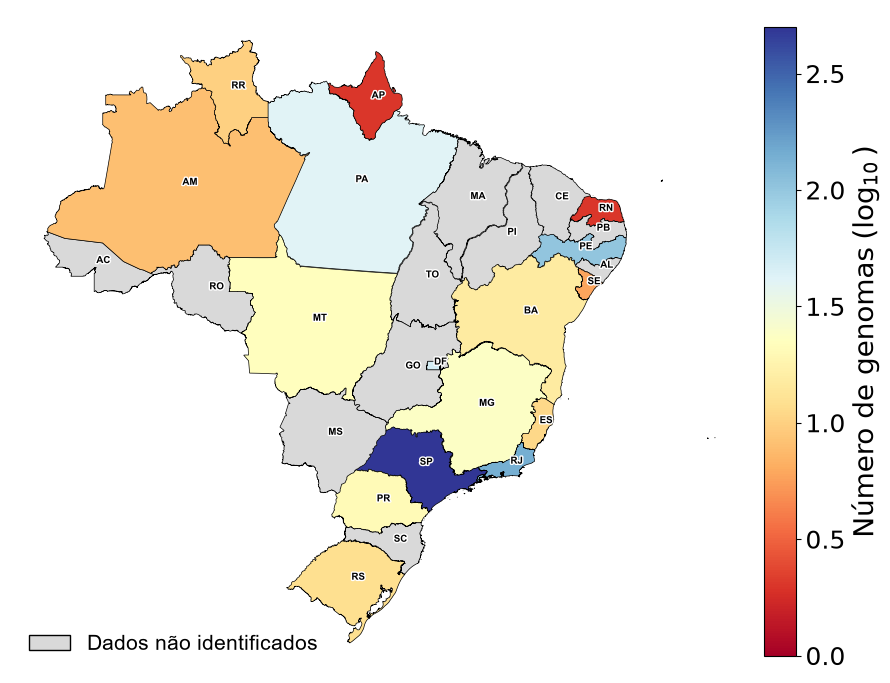

In [ ]:
from matplotlib.cm import ScalarMappable


# ============================================================
# 1. Ler shapefile dos estados brasileiros
# ============================================================

brasil_estados = geobr.read_state(year=2020)

# ============================================================
# 2. Padronizar nomes dos estados no mapa
# ============================================================

brasil_estados["estado_norm"] = (
    brasil_estados["name_state"]
    .apply(lambda x: unidecode(x).upper())
)

# ============================================================
# 3. Padronizar nomes dos estados na sua tabela
# ============================================================

df_brasil["estado_norm"] = (
    df_brasil["nome_estados"]
    .astype(str)
    .str.strip()
    .apply(lambda x: unidecode(x).upper())
)

df_brasil["estado_norm"] = df_brasil["estado_norm"].replace({"FEDERAL DISTRICT": "DISTRITO FEDERAL"})

# ============================================================
# 4. Frequência por estado
# ============================================================

df_brasil_frequencia = (df_brasil["estado_norm"].value_counts().rename_axis("estado_norm").reset_index(name="frequencia"))

# log10 da frequência
df_brasil_frequencia["frequencia"] = np.log10(df_brasil_frequencia["frequencia"])

# ============================================================
# 5. Merge com o mapa
# ============================================================

brasil_estados = brasil_estados.merge(df_brasil_frequencia,on="estado_norm",how="left")

# ============================================================
# 6. Configuração da escala de cores
# ============================================================

norm = Normalize(vmin=0, vmax=2.7)

cmap = plt.colormaps["RdYlBu"]

# ============================================================
# 7. Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 9),
    facecolor="white"
)

ax.set_facecolor("white")

for _, row in brasil_estados.iterrows():

    if pd.isna(row["frequencia"]):
        cor = "#d9d9d9"
    else:
        cor = cmap(norm(row["frequencia"]))

    gpd.GeoSeries(
        [row["geometry"]],
        crs=brasil_estados.crs
    ).plot(
        ax=ax,
        color=cor,
        edgecolor="black",
        linewidth=0.5
    )

ax.set_axis_off()

# ============================================================
# 8. Barra de cores
# ============================================================

sm = ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation="vertical",
    pad=0.02,
    fraction=0.04
)

cbar.set_label(
    r"$\mathrm{Número\ de\ genomas}\;(\log_{10})$",
    fontsize=20,
    fontfamily="Arial"
)

cbar.ax.tick_params(labelsize=18)

for tick in cbar.ax.get_xticklabels():
    tick.set_fontfamily("Arial")


import matplotlib.patheffects as pe

for _, row in brasil_estados.iterrows():

    centroide = row.geometry.centroid

    txt = ax.text(
        centroide.x+0.5,
        centroide.y+0.2,
        row["abbrev_state"],   # sigla do estado
        ha="center",
        va="center",
        fontsize=7,
        fontweight="bold",
        color="black",
        family="Arial",
        zorder=100
    )

    txt.set_path_effects([
        pe.withStroke(
            linewidth=2,
            foreground="white"
        )
    ])

# ============================================================
# 9. Legenda sem dados
# ============================================================

legenda_sem_dados = Patch(facecolor="#d9d9d9",edgecolor="black",label="Dados não identificados")

ax.legend(handles=[legenda_sem_dados],loc="lower left",
     frameon=False,prop={"family": "Arial", "size": 15})

# ============================================================
# 10. Salvar figura
# ============================================================

plt.tight_layout()

plt.savefig(
    "mapa_estados_brasil2.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()